# 03 · The SVM yardstick, a fair comparison, and the threshold

**Read first:** `01_theory/05_svm_comparison.md`, `01_theory/06_evaluation.md`

1. TF-IDF features + a calibrated LinearSVC (the yardstick — from the library, on purpose)
2. comparing NB and SVM **fairly**: same folds, features refitted inside every fold, mean ± std
3. why 0.5 is the wrong threshold for a spam filter
4. choosing the threshold on **validation**, with a precision floor of 0.98, then testing once

In [1]:
import csv
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP, TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

URL_RE = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
WORD_RE = re.compile(r"[a-z']+")

def tokenize(text):
    text = URL_RE.sub(" URLTOKEN ", text).lower().replace("urltoken", "URLTOKEN")
    out = []
    for i, part in enumerate(text.split("URLTOKEN")):
        if i:
            out.append("URLTOKEN")
        out += [w for w in WORD_RE.findall(part) if len(w) >= 3 and w not in STOP]
    return out

texts, y = [], []
with open(Path("../data/sms_spam.csv"), encoding="utf-8") as f:
    for row in csv.DictReader(f):
        texts.append(row["text"])
        y.append(1 if row["label"] == "spam" else 0)
texts, y = np.array(texts, dtype=object), np.array(y)

In this notebook we let scikit-learn do the counting (`CountVectorizer`, `TfidfVectorizer`) with **our**
tokenizer, and use `MultinomialNB` — notebook 02 proved our NB gives the same numbers. The point here is
the *method* of comparing, not the models.

In [2]:
def make_nb():
    vec = CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, ngram_range=(1, 2), max_features=5000)
    return vec, MultinomialNB(alpha=1.0)

def make_svm():
    vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, ngram_range=(1, 2), max_features=5000)
    return vec, CalibratedClassifierCV(LinearSVC(C=1.0, random_state=42), method="sigmoid", cv=5)

## 1. Same folds, refit inside every fold

The vectorizer is **fitted inside the loop** on the training part only. Fitting it once on all messages
would let the test fold choose the vocabulary and the IDF values — a leak.

In [3]:
def stratified_folds(y, k=5, seed=42):
    rng = np.random.default_rng(seed)
    fold = np.empty(len(y), int)
    for c in (0, 1):
        rows = rng.permutation(np.flatnonzero(y == c))
        fold[rows] = np.arange(len(rows)) % k
    return [(np.flatnonzero(fold != f), np.flatnonzero(fold == f)) for f in range(k)]

def f1_spam(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    p = tp / max(np.sum(y_pred == 1), 1); r = tp / max(np.sum(y_true == 1), 1)
    return 0 if p + r == 0 else 2 * p * r / (p + r)

results = {"naive bayes": [], "svm": []}
for tr, te in stratified_folds(y):
    for name, factory in (("naive bayes", make_nb), ("svm", make_svm)):
        vec, model = factory()                          # FRESH objects every fold
        model.fit(vec.fit_transform(texts[tr]), y[tr])
        results[name].append(f1_spam(y[te], model.predict(vec.transform(texts[te]))))

for name, s in results.items():
    print(f"{name:12s} F1(spam) = {np.mean(s):.3f} ± {np.std(s):.3f}   folds: {np.round(s, 3)}")
gap = np.mean(results["svm"]) - np.mean(results["naive bayes"])
print(f"gap {gap:+.3f}  vs. fold spread ~{max(np.std(v) for v in results.values()):.3f}")

naive bayes  F1(spam) = 0.925 ± 0.010   folds: [0.929 0.917 0.932 0.911 0.937]
svm          F1(spam) = 0.936 ± 0.018   folds: [0.963 0.92  0.949 0.915 0.93 ]
gap +0.010  vs. fold spread ~0.018


If the gap is not clearly larger than the spread, say so in the book — "the SVM is a little better on
average, but within the noise" is an honest, defensible result. And even if the SVM wins, NB stays the
primary model because its explanations are exact (theory §4.8).

## 2. Train / validation / test: 70 / 15 / 15

In [4]:
rng = np.random.default_rng(7)
perm = rng.permutation(len(y))
a, b = int(.70 * len(y)), int(.85 * len(y))
tr, va, te = perm[:a], perm[a:b], perm[b:]

vec, nb = make_nb()
nb.fit(vec.fit_transform(texts[tr]), y[tr])
p_val = nb.predict_proba(vec.transform(texts[va]))[:, 1]
p_test = nb.predict_proba(vec.transform(texts[te]))[:, 1]

## 3. Precision and recall at every threshold

Raising the threshold → fewer real messages hidden (precision ↑), more spam gets through (recall ↓).

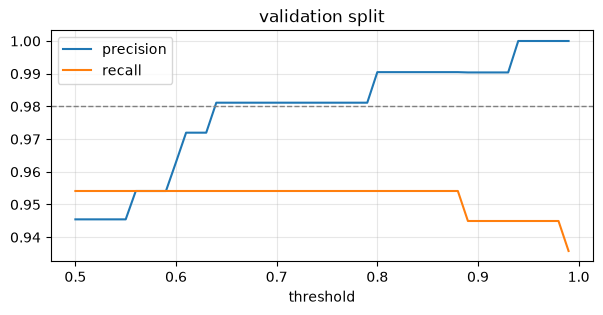

In [5]:
def at(probs, y_true, t):
    pred = probs >= t
    tp = np.sum(pred & (y_true == 1)); fp = np.sum(pred & (y_true == 0)); fn = np.sum(~pred & (y_true == 1))
    prec = tp / (tp + fp) if tp + fp else 1.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return prec, rec, fp

ts = np.round(np.arange(0.50, 0.995, 0.01), 2)
pr = np.array([at(p_val, y[va], t)[:2] for t in ts])
plt.figure(figsize=(7, 3))
plt.plot(ts, pr[:, 0], label="precision"); plt.plot(ts, pr[:, 1], label="recall")
plt.axhline(0.98, ls="--", c="gray", lw=1)
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("validation split")
plt.show()

## 4. The rule: the highest recall subject to precision ≥ 0.98

Hiding a real message (false positive) is far worse than letting one spam through. So we do not maximise
accuracy — we set a floor on precision and take the best recall above it. Chosen on **validation** only.

In [6]:
def choose_threshold(probs, y_true, min_precision=0.98):
    best = None
    for t in ts:
        prec, rec, _ = at(probs, y_true, t)
        if prec >= min_precision and (best is None or rec > best[2]):
            best = (t, prec, rec)
    if best is None:
        raise ValueError("no threshold reaches the precision floor")
    return best

t, prec, rec = choose_threshold(p_val, y[va])
print(f"chosen on validation: threshold {t:.2f}  (precision {prec:.3f}, recall {rec:.3f})")

chosen on validation: threshold 0.64  (precision 0.981, recall 0.954)


## 5. The test split — opened once, at the end

In [7]:
for name, thr in (("default 0.50", 0.5), (f"chosen {t:.2f}", t)):
    prec, rec, fp = at(p_test, y[te], thr)
    n_ham = np.sum(y[te] == 0)
    print(f"{name:13s} precision {prec:.3f}  recall {rec:.3f}  false positives per 1,000 ham {1000 * fp / n_ham:.1f}")

default 0.50  precision 0.991  recall 0.847  false positives per 1,000 ham 1.4
chosen 0.64   precision 0.991  recall 0.847  false positives per 1,000 ham 1.4


Did the threshold change anything on test? Look at where Naive Bayes puts its probabilities:

test messages with P(spam) between 0.05 and 0.95: 79 of 837


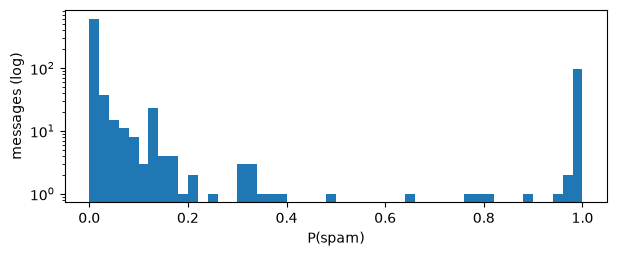

In [8]:
print(f"test messages with P(spam) between 0.05 and 0.95: {np.sum((p_test > .05) & (p_test < .95))} of {len(p_test)}")
plt.figure(figsize=(7, 2.5))
plt.hist(p_test, bins=50); plt.yscale("log"); plt.xlabel("P(spam)"); plt.ylabel("messages (log)")
plt.show()

About nine probabilities in ten are below 0.05 or above 0.95. Naive Bayes is **badly calibrated** (theory §4.2): it multiplies
evidence as if words were independent, so it is always very sure. Very few messages sit between 0.5 and
the chosen threshold, which is why moving it changes little here. With the calibrated SVM (try exercise 3
below) the threshold matters more. Either way, the threshold is a documented decision made on validation.

Compare with your success metrics (theory §6.6): precision ≥ 0.98, recall ≥ 0.85, ≤ 20 false positives per
1,000 ham. If the chosen threshold misses one of them on test, **report it** — do not go back and tune on
test.

## ✍️ Try it yourself

1. Choose the threshold on the **test** split instead. How much better does it look? Why is that number
   worthless?
2. Change the floor to 0.95 and 0.995. What happens to recall? Which would you pick for your own inbox?
3. Replace NB with the SVM in sections 2–5. Which reaches the floor with the higher recall?

Then solve exercises 12–13 in `03_exercises/`.